# 098｜规模规律与实验外推

CPU离线实验。先读lecture.md和lab.md，从本讲目录按序运行；重跑覆盖本目录outputs。

In [1]:
from pathlib import Path
import json, numpy as np
import experiment as e
print("Ready: CPU experiment")

Ready: CPU experiment


## 运行完整协议

不跳过失败配置，不将墙钟时间视为固定硬件保证。

In [2]:
e.main()

{
  "protocol": "Fixed data, optimizer, steps; widths 4/8/16/32 fit, width 64 held out. Test set used to characterize scale, not to select settings. Not a compute-optimal experiment.",
  "widths": [
    4,
    8,
    16,
    32,
    64
  ],
  "seeds": [
    11,
    23,
    37,
    51,
    73
  ],
  "parameters": [
    25,
    49,
    97,
    193,
    385
  ],
  "mean_test_mse": [
    0.03629040084779263,
    0.01636207476258278,
    0.01331074107438326,
    0.011229974031448365,
    0.01114363521337509
  ],
  "log_fit_intercept": -1.7476185501208419,
  "log_fit_slope": -0.5455992836604951,
  "in_sample_log_residuals": [
    0.18763288222465935,
    -0.24179621971426402,
    -0.07560638716371937,
    0.1297697246533236
  ],
  "predicted_mse": [
    0.030081801410966266,
    0.02083766907615782,
    0.014356139580487407,
    0.009863259890473841,
    0.006766956508408624
  ],
  "seed_bootstrap_95_low": [
    0.026622289279120345,
    0.01930324329139317,
    0.013780351317618029,
    0.0

In [3]:
metrics = json.loads(Path("outputs/metrics.json").read_text())
print("Result fields:", list(metrics))

Result fields: ['protocol', 'widths', 'seeds', 'parameters', 'mean_test_mse', 'log_fit_intercept', 'log_fit_slope', 'in_sample_log_residuals', 'predicted_mse', 'seed_bootstrap_95_low', 'seed_bootstrap_95_high', 'seed_bootstrap_slope_95', 'heldout_relative_error', 'noise_variance', 'records']


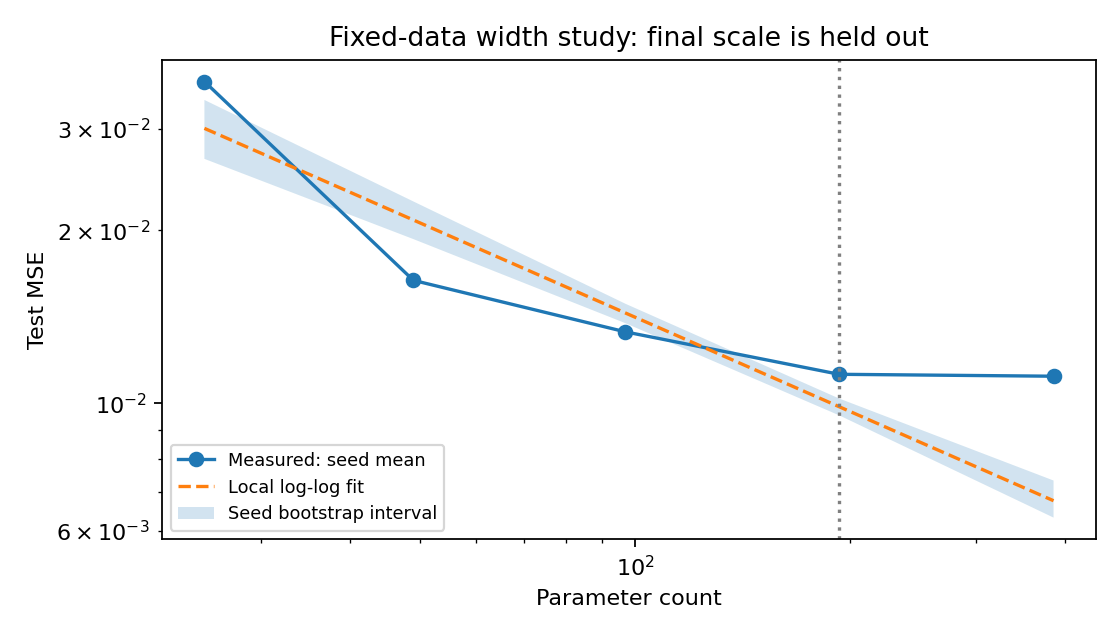

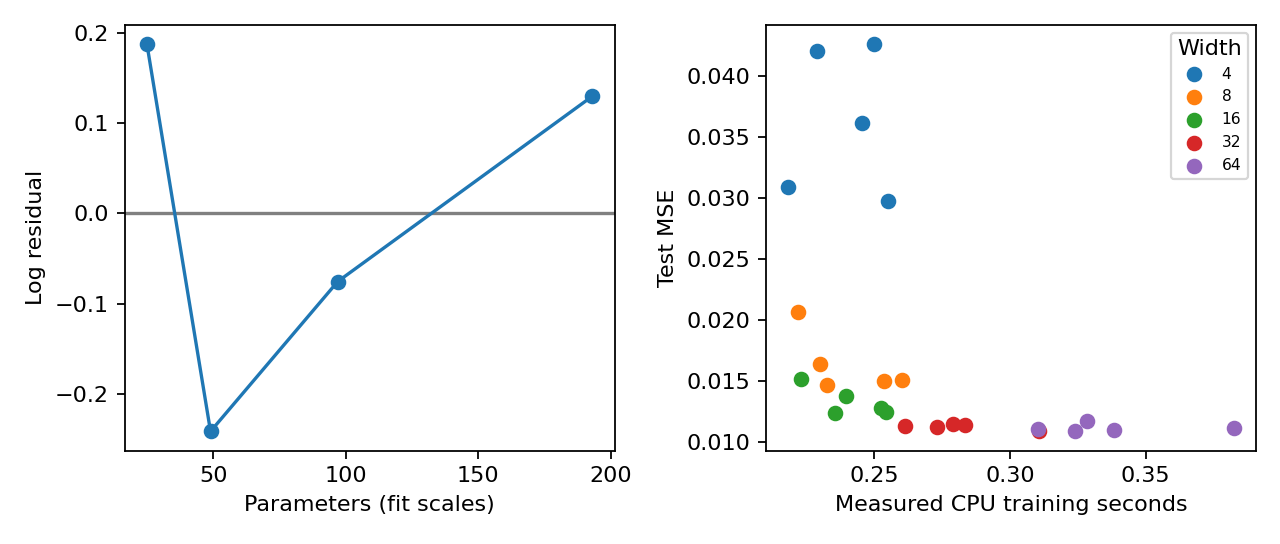

In [4]:
from IPython.display import display, Image
for path in sorted(Path("figures").glob("*.png")):
    display(Image(filename=str(path)))

## 独立断言

此处运行tests.py中的全部测试；失败必须先诊断，不能删除断言。

In [5]:
import unittest, tests
result=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromModule(tests))
assert result.wasSuccessful()

test_accounting (tests.Tests.test_accounting) ... 

ok


test_analytic_power (tests.Tests.test_analytic_power) ... 

ok


test_fit_excludes_holdout (tests.Tests.test_fit_excludes_holdout) ... 

...

test_relative_error (tests.Tests.test_relative_error) ... 

ok


test_split_and_finite (tests.Tests.test_split_and_finite) ... 

ok


----------------------------------------------------------------------
Ran 7 tests in 0.021s

OK


In [6]:
print("解释题：哪些结果是真实CPU测量？哪些属于模型假设？哪些结论需要新实验？")

解释题：哪些结果是真实CPU测量？哪些属于模型假设？哪些结论需要新实验？
